In [1]:
# Task 2: Housing Price Prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset summary:")
print(df.describe())

Dataset shape: (20640, 9)

First five rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Dataset summary:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20

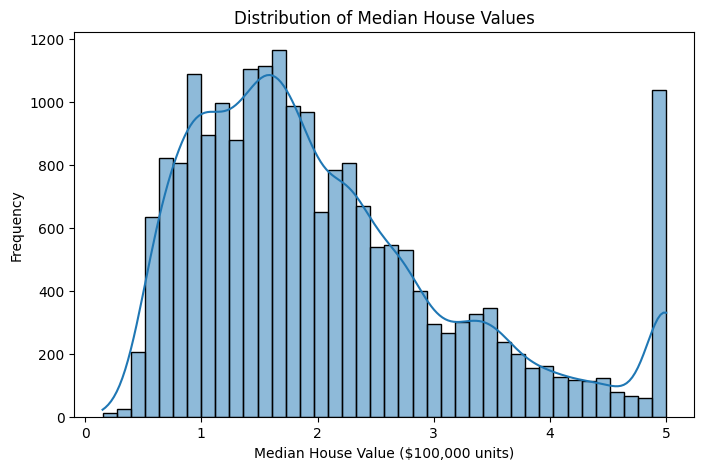

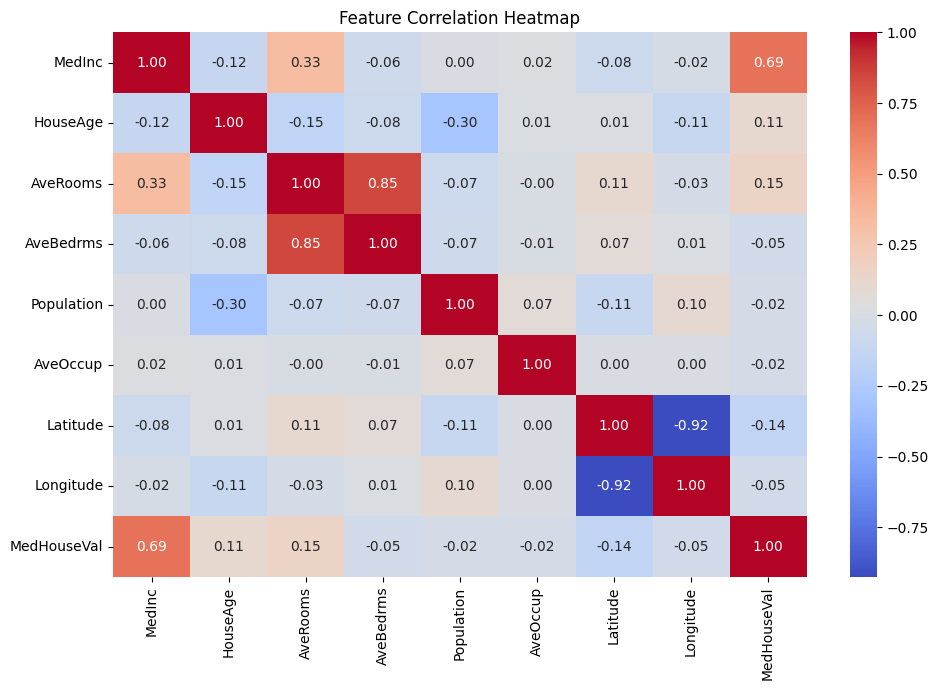

Data types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Duplicate rows: 0


In [2]:
# Target distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Check categorical columns
print("Data types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

# Separate features and target
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

# Split before fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create interaction features
poly = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Impute missing values and scale features
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_ready = scaler.fit_transform(
    imputer.fit_transform(X_train_poly)
)
X_test_ready = scaler.transform(
    imputer.transform(X_test_poly)
)

print("Training samples:", X_train_ready.shape[0])
print("Testing samples:", X_test_ready.shape[0])
print("Features after interaction:", X_train_ready.shape[1])
print("Missing values in target:", y.isnull().sum())

Training samples: 16512
Testing samples: 4128
Features after interaction: 36
Missing values in target: 0


In [7]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Train OLS model
ols = LinearRegression()
ols.fit(X_train_ready, y_train)

# Find the best Ridge model
ridge_search = GridSearchCV(
    Ridge(),
    {"alpha": [0.1, 1, 10, 100]},
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_search.fit(X_train_ready, y_train)
ridge = ridge_search.best_estimator_

# Find the best Lasso model
lasso_search = GridSearchCV(
    Lasso(max_iter=10000),
    {"alpha": [0.001, 0.01, 0.1, 1]},
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
lasso_search.fit(X_train_ready, y_train)
lasso = lasso_search.best_estimator_

# Store all trained models
models_reg = {
    "OLS": ols,
    "Ridge": ridge,
    "Lasso": lasso
}

# Evaluate models
results_reg = []
predictions = {}

for name, model in models_reg.items():
    pred = model.predict(X_test_ready)
    predictions[name] = pred

    results_reg.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

results_reg_df = pd.DataFrame(results_reg)

print("Best Ridge alpha:", ridge_search.best_params_)
print("Best Lasso alpha:", lasso_search.best_params_)
print("\nRegression Model Comparison:")
print(results_reg_df.round(4).to_string(index=False))

Best Ridge alpha: {'alpha': 100}
Best Lasso alpha: {'alpha': 0.01}

Regression Model Comparison:
Model   RMSE    MAE     R2
  OLS 0.7033 0.4809 0.6225
Ridge 0.7440 0.5202 0.5776
Lasso 0.7514 0.5329 0.5692


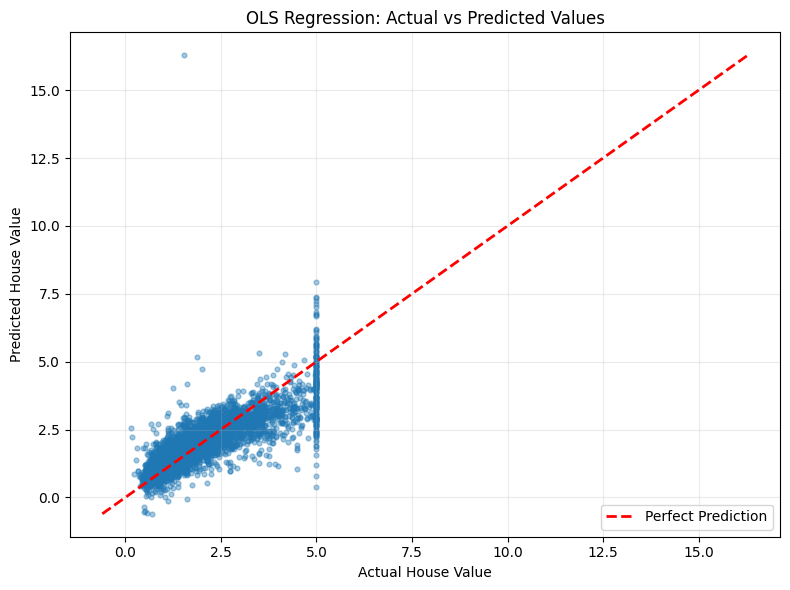

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions["OLS"], alpha=0.4, s=12)

min_val = min(y_test.min(), predictions["OLS"].min())
max_val = max(y_test.max(), predictions["OLS"].max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("OLS Regression: Actual vs Predicted Values")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

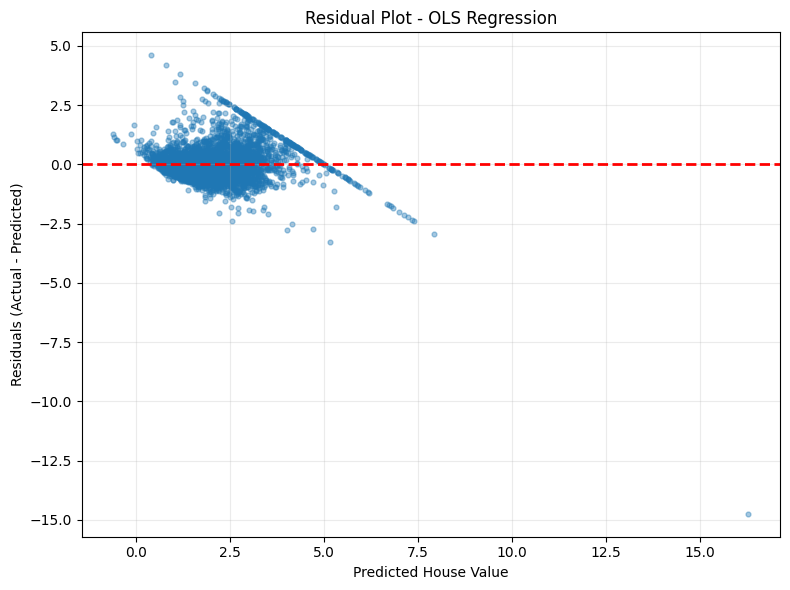

In [9]:
# Calculate residuals for the OLS model
residuals = y_test - predictions["OLS"]

plt.figure(figsize=(8, 6))
plt.scatter(predictions["OLS"], residuals, alpha=0.4, s=12)
plt.axhline(y=0, color="red", linestyle="--", linewidth=2)

plt.xlabel("Predicted House Value")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - OLS Regression")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()